<a href="https://colab.research.google.com/github/isuru-phi6/ionospheric_plasma_bubbles/blob/main/Climatology_Statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Objective 1: Occurrence climatology of plasma bubbles over the Sri Lanka sector

**Data:** `passes_night.csv`, made by the main notebook (Step 7). One row per Swarm night pass over 70–90°E, ±20° magnetic latitude, 18–06 LT, 2014 to present.

**Target:** `bubble` = 1 if the bubble index (IBI) flagged at least one second of the pass as a bubble.

**Questions answered here (Objective O1):**
1. How often do bubbles occur, and how does this change with **local time**, **season**, **solar activity** and **geomagnetic activity**?
2. Is occurrence different in **Solar Cycle 25** compared with **Cycle 24**, once solar flux is taken into account?
3. Which of these factors still matter when they are all considered **together** (multivariable logistic regression)?
4. Are the conclusions **robust** to how a "bubble pass" is defined and to the overlap between Swarm A and C?

**Statistics used:** proportions with Wilson and cluster-bootstrap confidence intervals, and logistic regression (GLM, binomial) with **cluster-robust standard errors by night**. All passes on the same night share the same conditions, and Swarm A and C often see the same bubble, so passes are not fully independent.

Run the cells from top to bottom. Figures go to `figures/O1/` and tables to `results/O1/` in your Drive folder.

---
## 1. Load the data from Google Drive
The main notebook saved the file to `MyDrive/EPB_SriLanka/results/passes_night.csv`. If you saved it somewhere else, change `DATA_FILE` below.

In [ ]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/EPB_SriLanka")
except ImportError:
    BASE_DIR = Path(os.environ.get("EPB_DIR", "EPB_SriLanka"))

DATA_FILE = BASE_DIR / "results" / "passes_night.csv"
FIG_DIR = BASE_DIR / "figures" / "O1"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = BASE_DIR / "results" / "O1"; TAB_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

p = pd.read_csv(DATA_FILE, parse_dates=["t_start", "t_end", "t_eq"])
print(f"Loaded {len(p):,} night passes, {p['t_eq'].min():%Y-%m-%d} to {p['t_eq'].max():%Y-%m-%d}")

Mounted at /content/drive
Loaded 11,633 night passes, 2014-01-01 to 2026-10-31


### Variables used in this notebook
We build a few grouping variables:

| Variable | Meaning |
|---|---|
| `LT2` | 2-hour local-time bins: 18–20, 20–22, …, 04–06 |
| `season` | Lloyd seasons: **March equinox** (Mar–Apr), **June solstice** (May–Aug), **September equinox** (Sep–Oct), **December solstice** (Nov–Feb) |
| `F107_cat` | solar activity from the 81-day mean F10.7: low < 90, moderate 90–130, high 130–170, very high > 170 sfu |
| `Kp_cat` | geomagnetic activity: quiet (Kp ≤ 2), moderate (2–4), active (> 4) |
| `period` | Cycle 24 decline (2014–19), Cycle 25 rise (2020–22), Cycle 25 maximum (2023–) |
| `night_id` | the local night the pass belongs to (evening and the following morning share one ID). Used to group dependent passes |
| `bubble10` | stricter label: at least **10 seconds** (about 75 km of track) flagged as bubble |

In [ ]:
p["LT_h"] = np.floor(p["LT"]).astype(int)
lt2_labels = ["18-20", "20-22", "22-24", "00-02", "02-04", "04-06"]
p["LT2"] = pd.Categorical(np.array(lt2_labels)[(p["LT_from18"] // 2).astype(int).clip(0, 5)],
                          categories=lt2_labels, ordered=True)

season_map = {1: "Dec solstice", 2: "Dec solstice", 11: "Dec solstice", 12: "Dec solstice",
              3: "Mar equinox", 4: "Mar equinox", 9: "Sep equinox", 10: "Sep equinox",
              5: "Jun solstice", 6: "Jun solstice", 7: "Jun solstice", 8: "Jun solstice"}
season_order = ["Mar equinox", "Jun solstice", "Sep equinox", "Dec solstice"]
p["season"] = pd.Categorical(p["month"].map(season_map), categories=season_order, ordered=True)

f107_labels = ["low (<90)", "moderate (90-130)", "high (130-170)", "very high (>170)"]
p["F107_cat"] = pd.cut(p["F107_81"], [0, 90, 130, 170, 400], labels=f107_labels)
p["Kp_cat"] = pd.cut(p["Kp"], [-0.1, 2, 4, 9.1], labels=["quiet (0-2)", "moderate (2-4)", "active (>4)"])

period_order = ["C24 decline (2014-19)", "C25 rise (2020-22)", "C25 maximum (2023-)"]
p["period"] = pd.Categorical(pd.cut(p["year"], [2013, 2019, 2022, 2100], labels=period_order),
                             categories=period_order, ordered=True)

# local night: shift local time back 12 h so 18 LT and the following 06 LT share a date
local_time = p["t_eq"] + pd.to_timedelta(p["lon_eq"] / 15, unit="h")
p["night_id"] = (local_time - pd.Timedelta("12h")).dt.strftime("%Y-%m-%d")
p["bubble10"] = (p["n_bubble"] >= 10).astype(int)

print("Nights:", p["night_id"].nunique(), "| passes per night (mean):", round(len(p) / p["night_id"].nunique(), 2))
p[["LT2", "season", "F107_cat", "Kp_cat", "period"]].describe()

Nights: 4607 | passes per night (mean): 2.53


,LT2,season,F107_cat,Kp_cat,period
count,11633,11633,11595,11633,11633
unique,6,4,4,3,3
top,20-22,Jun solstice,low (<90),quiet (0-2),C24 decline (2014-19)
freq,1999,3963,4981,7673,5426


---
## 2. Data overview: is the sampling even?
Before comparing rates, check that every year, satellite, local time and month is sampled. If one local time were sampled only at solar minimum, its rate would look low for the wrong reason. Swarm's orbit slowly drifts through all local times (about every 4 months for A/C and 5 for B), so coverage should be fairly even.

sat      A     B     C    All
year                         
2014   288   285   288    861
2015   303   297   303    903
2016   321   293   316    930
2017   302   301   309    912
2018   306   296   305    907
2019   310   300   303    913
2020   295   305   313    913
2021   296   304   301    901
2022   296   301   306    903
2023   299   302   304    905
2024   305   301   303    909
2025   310   305   301    916
2026   259   248   253    760
All   3890  3838  3905  11633


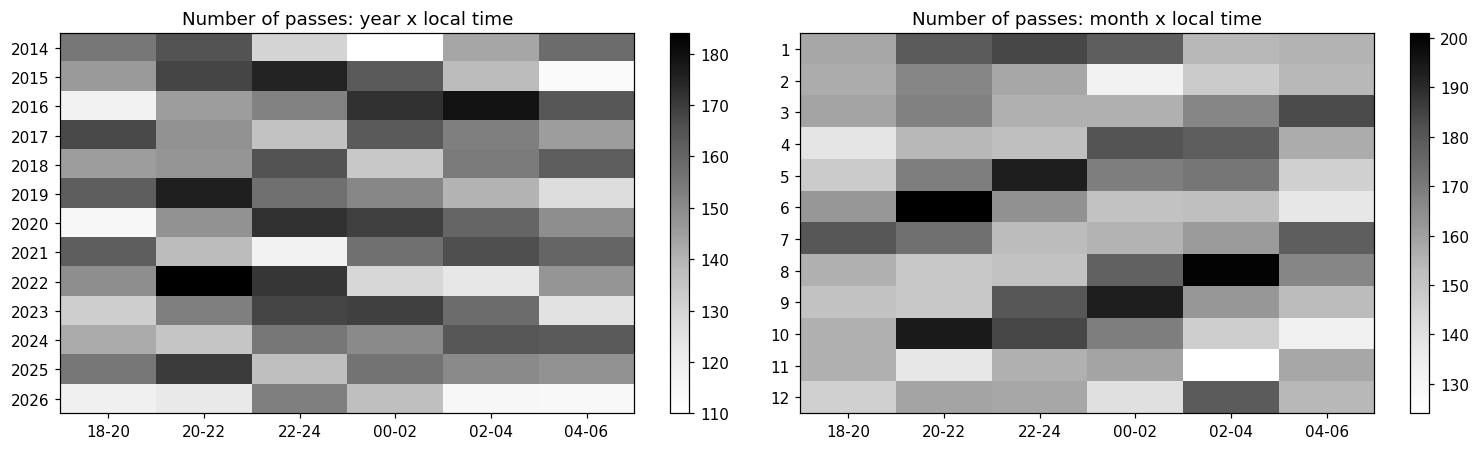

Missing values:
 F107         159
F107_81       38
Kp             0
Dst_min24      2
dtype: int64


In [ ]:
print(pd.crosstab(p["year"], p["sat"], margins=True))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
cov = pd.crosstab(p["year"], p["LT2"])
im = axes[0].imshow(cov.values, aspect="auto", cmap="Greys")
axes[0].set_xticks(range(6)); axes[0].set_xticklabels(lt2_labels)
axes[0].set_yticks(range(len(cov))); axes[0].set_yticklabels(cov.index)
axes[0].set_title("Number of passes: year x local time"); plt.colorbar(im, ax=axes[0])
cov2 = pd.crosstab(p["month"], p["LT2"])
im = axes[1].imshow(cov2.values, aspect="auto", cmap="Greys")
axes[1].set_xticks(range(6)); axes[1].set_xticklabels(lt2_labels)
axes[1].set_yticks(range(12)); axes[1].set_yticklabels(range(1, 13))
axes[1].set_title("Number of passes: month x local time"); plt.colorbar(im, ax=axes[1])
for ax in axes: ax.grid(False)
plt.tight_layout(); savefig("O1_sampling_coverage"); plt.show()
print("Missing values:\n", p[["F107", "F107_81", "Kp", "Dst_min24"]].isna().sum())

---
## 3. How good is the bubble label?
`n_bubble` is the number of seconds in a pass that IBI flagged as bubble. Very short detections (1–3 seconds, a few km of track) can be noise rather than a real bubble. We also check `max_prob` (IBI's `Bubble_Probability`) to see whether it can be used as a quality filter.

Bubble passes: 718  (6.2% of all passes)
Seconds flagged per bubble pass:
 count    718.0
mean      71.0
std       86.4
min        1.0
25%        6.0
50%       38.0
75%      102.8
max      556.0
Name: n_bubble, dtype: float64
Bubble passes with only 1-3 flagged seconds: 18.2%


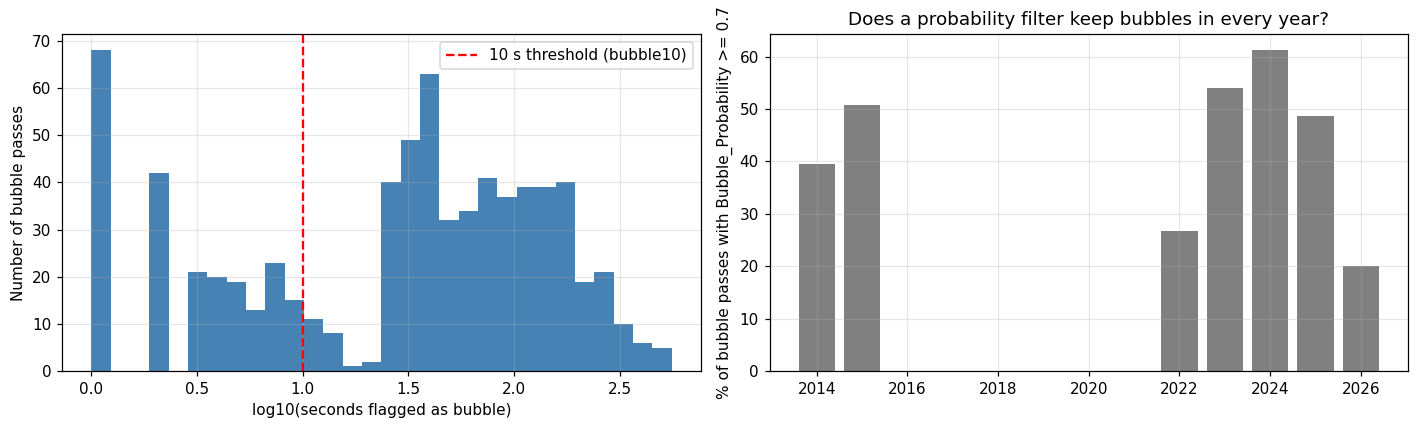

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% of bubble passes with probability >= 0.7,39.6,50.8,0.0,0.0,0.0,0.0,0.0,0.0,26.8,54.0,61.2,48.7,20.0


In [ ]:
b = p[p["bubble"] == 1]
print(f"Bubble passes: {len(b)}  ({len(b)/len(p):.1%} of all passes)")
print("Seconds flagged per bubble pass:\n", b["n_bubble"].describe().round(1))
print(f"Bubble passes with only 1-3 flagged seconds: {(b['n_bubble'] <= 3).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(b["n_bubble"]), bins=30, color="steelblue")
axes[0].set_xlabel("log10(seconds flagged as bubble)"); axes[0].set_ylabel("Number of bubble passes")
axes[0].axvline(1, color="red", ls="--", label="10 s threshold (bubble10)"); axes[0].legend()
share_prob = b.groupby("year")["max_prob"].apply(lambda s: (s >= 0.7).mean())
axes[1].bar(share_prob.index, 100 * share_prob.values, color="grey")
axes[1].set_ylabel("% of bubble passes with Bubble_Probability >= 0.7")
axes[1].set_title("Does a probability filter keep bubbles in every year?")
plt.tight_layout(); savefig("O1_label_quality"); plt.show()
display((100 * share_prob).round(1).to_frame("% of bubble passes with probability >= 0.7").T)

**How to read this.**
- `Bubble_Probability` rarely reaches 0.7 in solar-minimum years. A "probability ≥ 0.7" label would remove nearly every bubble in those years and create a fake solar-cycle trend, so it is **not a usable quality filter**. We use the **duration** of the detection instead (`bubble10`, at least 10 s) as the stricter label.
- Detections of 1–3 seconds are a small, noisy part of the data. Section 11 checks that the conclusions don't depend on them.

---
## 4. Are passes independent? (Swarm A and C)
Swarm A and C fly side by side, about 1.4° apart in longitude. When both cross the region within the same half hour, they almost always see the same thing. Treating their passes as independent would make confidence intervals too narrow, and p-values too small.

In [ ]:
ac = p[p["sat"].isin(["A", "C"])].copy()
ac["slot"] = ac["t_eq"].dt.floor("30min")
pair = ac.pivot_table(index="slot", columns="sat", values="bubble", aggfunc="max").dropna()
tab = pd.crosstab(pair["A"], pair["C"]); print(f"{len(pair)} A-C pass pairs within 30 min\n", tab)
agree = (pair["A"] == pair["C"]).mean()
p_c_given_a = pair.loc[pair["A"] == 1, "C"].mean()
print(f"\nAgreement: {agree:.1%}.  P(C sees bubble | A sees bubble) = {p_c_given_a:.1%}  vs overall rate {pair['C'].mean():.1%}")

3558 A-C pass pairs within 30 min
 C     0.0  1.0
A             
0.0  3280   48
1.0    57  173

Agreement: 97.0%.  P(C sees bubble | A sees bubble) = 75.2%  vs overall rate 6.2%


The two satellites are strongly dependent. So from here on:
- **Confidence intervals for rates** use a **cluster bootstrap**: whole nights are resampled, never single passes.
- **Regression models** use **cluster-robust standard errors grouped by night**.
- As a sensitivity check (Section 11), the main model is refitted with **Swarm C removed**.

In [ ]:
rng = np.random.default_rng(42)

def wilson(k, n):
    lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
    return lo, hi

def cluster_boot_ci(df, col="bubble", n_boot=2000):
    # 95% CI for a rate, resampling whole nights (clusters) with replacement
    g = df.groupby("night_id")[col].agg(["sum", "size"]).values
    if len(g) < 2:
        return np.nan, np.nan
    idx = rng.integers(0, len(g), (n_boot, len(g)))
    rates = g[idx, 0].sum(1) / g[idx, 1].sum(1)
    return np.percentile(rates, [2.5, 97.5])

def rate_table(df, by, col="bubble", boot=True):
    rows = []
    for key, g in df.groupby(by, observed=True):
        k, n = g[col].sum(), len(g)
        lo, hi = cluster_boot_ci(g, col) if boot else wilson(k, n)
        rows.append({**dict(zip(by if isinstance(by, list) else [by], key if isinstance(key, tuple) else [key])),
                     "n_passes": n, "n_bubble": int(k), "rate_%": 100 * k / n, "ci_low_%": 100 * lo, "ci_high_%": 100 * hi})
    return pd.DataFrame(rows)

def plot_rates(t, x, ax, label=None, **kw):
    ax.errorbar(range(len(t)) if t[x].dtype == object else t[x], t["rate_%"],
                yerr=[t["rate_%"] - t["ci_low_%"], t["ci_high_%"] - t["rate_%"]],
                marker="o", capsize=3, label=label, **kw)
    if t[x].dtype == object:
        ax.set_xticks(range(len(t))); ax.set_xticklabels(t[x], rotation=20)

overall = rate_table(p.assign(all="all passes"), "all")
display(overall.round(2))

,all,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
0,all passes,11633,718,6.17,5.63,6.72


---
## 5. Year-to-year variation and the solar cycle

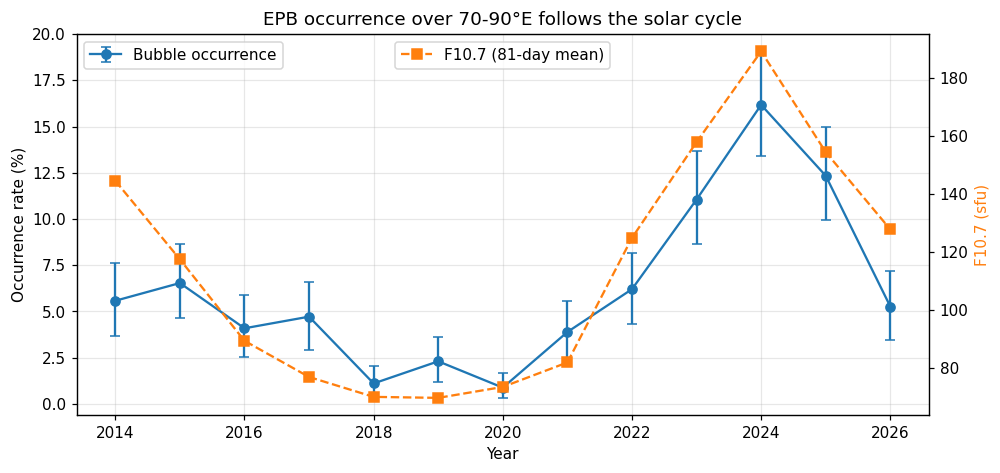

Spearman correlation between yearly rate and yearly F10.7: rho = 0.91, p = 0.0000 (n = 13 years)


,year,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
0,2014,861,48,5.57,3.67,7.64
1,2015,903,59,6.53,4.63,8.62
2,2016,930,38,4.09,2.56,5.87
3,2017,912,43,4.71,2.90,6.62
4,2018,907,10,1.10,0.34,2.04
5,2019,913,21,2.30,1.18,3.60
6,2020,913,8,0.88,0.32,1.64
7,2021,901,35,3.88,2.45,5.58
8,2022,903,56,6.20,4.34,8.16
9,2023,905,100,11.05,8.64,13.68


In [ ]:
yr = rate_table(p, "year")
f107_year = p.groupby("year")["F107_81"].mean()
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_rates(yr, "year", ax, color="tab:blue", label="Bubble occurrence")
ax.set_ylabel("Occurrence rate (%)"); ax.set_xlabel("Year")
ax2 = ax.twinx(); ax2.plot(f107_year.index, f107_year.values, color="tab:orange", ls="--", marker="s", label="F10.7 (81-day mean)")
ax2.set_ylabel("F10.7 (sfu)", color="tab:orange"); ax2.grid(False)
ax.legend(loc="upper left"); ax2.legend(loc="upper center")
ax.set_title("EPB occurrence over 70-90°E follows the solar cycle")
savefig("O1_rate_by_year"); plt.show()
rho, pval = stats.spearmanr(yr["rate_%"], f107_year.loc[yr["year"]].values)
print(f"Spearman correlation between yearly rate and yearly F10.7: rho = {rho:.2f}, p = {pval:.4f} (n = {len(yr)} years)")
display(yr.round(2))

**Note on 2026:** this year is incomplete, and the missing months (November–December) are a low-occurrence season. Its yearly rate is shown, but keep that in mind when you compare it.

---
## 6. Local time

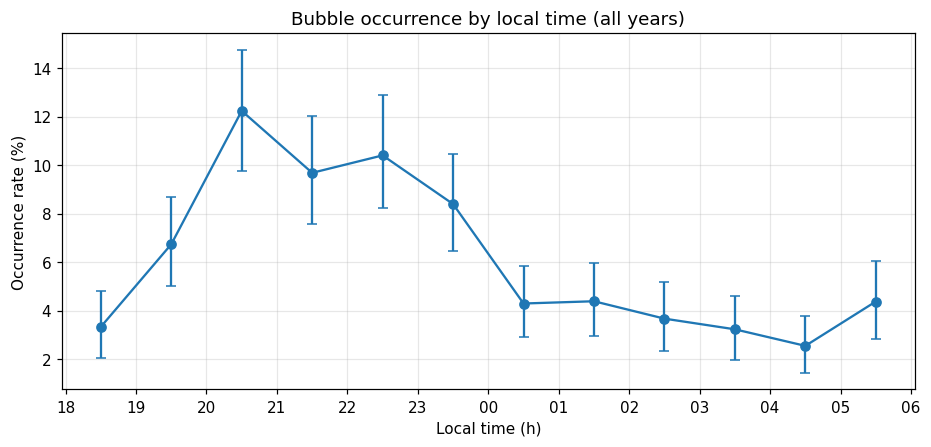

Peak local time: 20-21 LT, rate 12.2% (95% CI 9.7-14.8%)


,LT_h,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
6,18,872,29,3.33,2.03,4.80
7,19,995,67,6.73,5.02,8.68
8,20,997,122,12.24,9.75,14.76
9,21,1002,97,9.68,7.58,12.02
10,22,1000,104,10.40,8.22,12.88
11,23,989,83,8.39,6.45,10.46
0,0,979,42,4.29,2.92,5.85
1,1,981,43,4.38,2.97,5.96
2,2,982,36,3.67,2.32,5.16
3,3,961,31,3.23,1.98,4.61


In [ ]:
order = list(range(18, 24)) + list(range(0, 6))
lt = rate_table(p, "LT_h"); lt["order"] = lt["LT_h"].map({h: i for i, h in enumerate(order)})
lt = lt.sort_values("order")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.errorbar(lt["order"] + 0.5, lt["rate_%"], yerr=[lt["rate_%"] - lt["ci_low_%"], lt["ci_high_%"] - lt["rate_%"]],
            marker="o", capsize=3)
ax.set_xticks(range(13)); ax.set_xticklabels([f"{h:02d}" for h in order] + ["06"])
ax.set_xlabel("Local time (h)"); ax.set_ylabel("Occurrence rate (%)")
ax.set_title("Bubble occurrence by local time (all years)")
savefig("O1_rate_by_LT"); plt.show()
peak = lt.loc[lt["rate_%"].idxmax()]
print(f"Peak local time: {int(peak['LT_h']):02d}-{(int(peak['LT_h'])+1)%24:02d} LT, rate {peak['rate_%']:.1f}% "
      f"(95% CI {peak['ci_low_%']:.1f}-{peak['ci_high_%']:.1f}%)")
display(lt.drop(columns="order").round(2))

---
## 7. Season

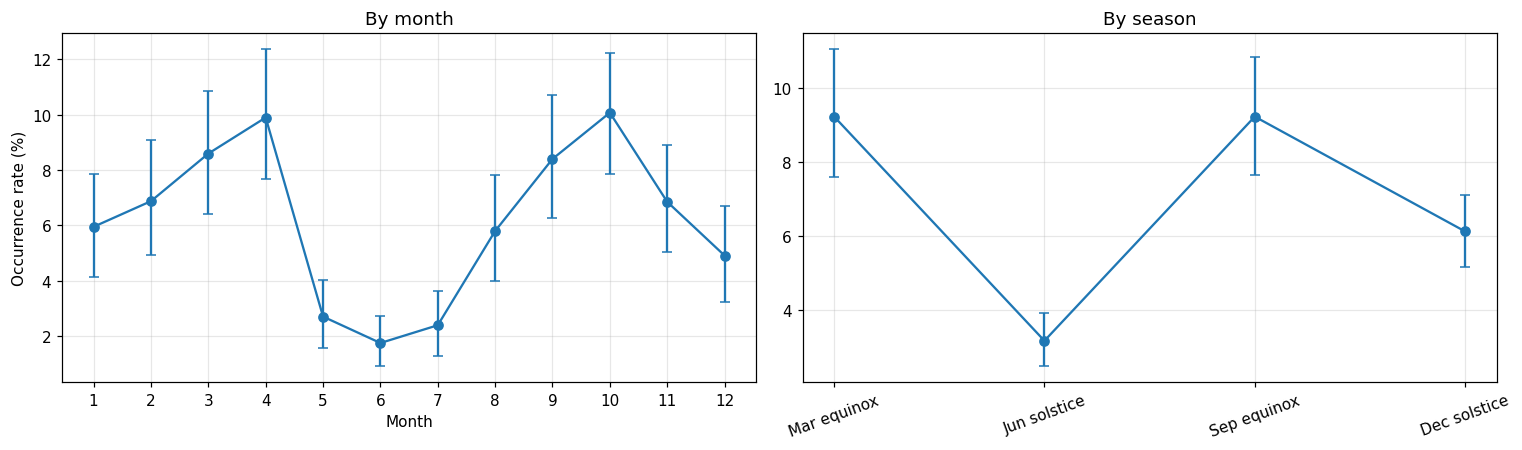

,season,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
0,Mar equinox,1949,180,9.24,7.61,11.06
1,Jun solstice,3963,126,3.18,2.50,3.94
2,Sep equinox,1971,182,9.23,7.65,10.84
3,Dec solstice,3750,230,6.13,5.16,7.12


In [ ]:
mo = rate_table(p, "month")
se = rate_table(p, "season")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
plot_rates(mo, "month", axes[0]); axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Occurrence rate (%)"); axes[0].set_title("By month")
plot_rates(se.assign(season=se["season"].astype(str)), "season", axes[1]); axes[1].set_title("By season")
plt.tight_layout(); savefig("O1_rate_by_month_season"); plt.show()
display(se.round(2))

### Month × local time map, and month × year map
Cells with fewer than 20 passes are grey (too few to trust). The second map shows how season and solar cycle combine.

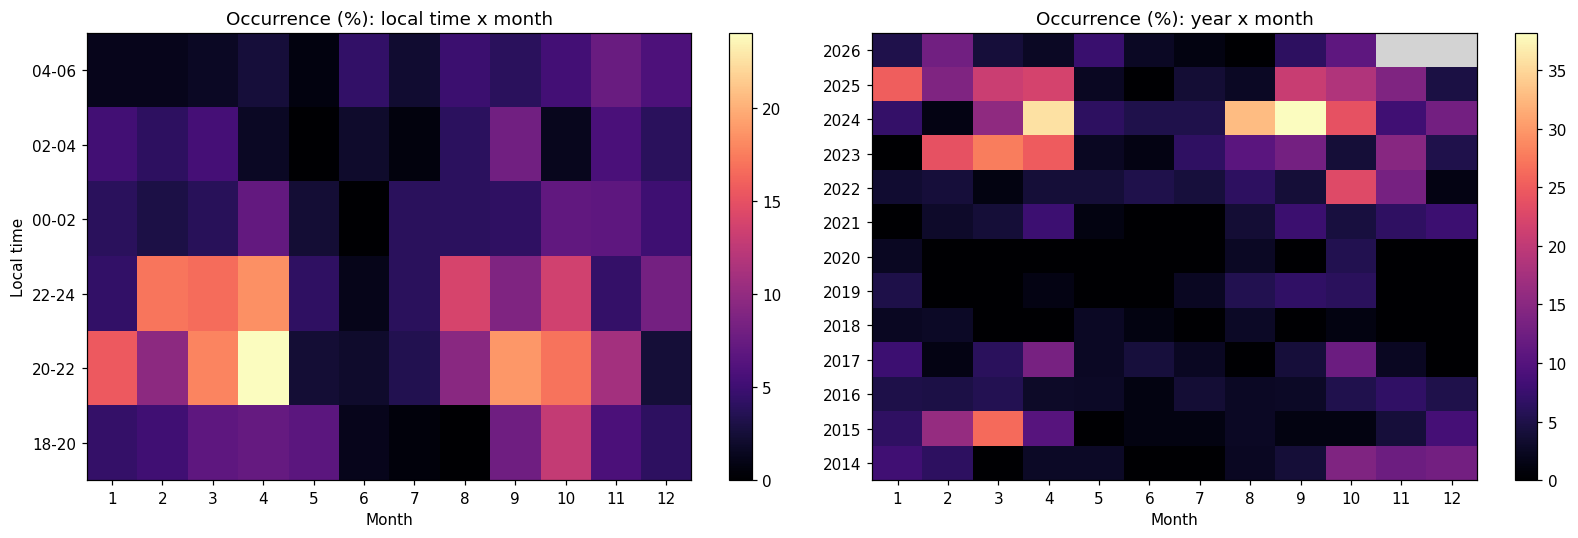

In [ ]:
def rate_grid(df, row, col, min_n=20):
    k = df.pivot_table(index=row, columns=col, values="bubble", aggfunc="sum", observed=False)
    n = df.pivot_table(index=row, columns=col, values="bubble", aggfunc="size", observed=False)
    return (100 * k / n).where(n >= min_n)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
g1 = rate_grid(p, "LT2", "month")
im = axes[0].imshow(g1.values, origin="lower", aspect="auto", cmap="magma", vmin=0)
axes[0].set_yticks(range(6)); axes[0].set_yticklabels(lt2_labels); axes[0].set_xticks(range(12)); axes[0].set_xticklabels(range(1, 13))
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Local time"); axes[0].set_title("Occurrence (%): local time x month")
plt.colorbar(im, ax=axes[0])
g2 = rate_grid(p, "year", "month", min_n=20)
im = axes[1].imshow(g2.values, origin="lower", aspect="auto", cmap="magma", vmin=0)
axes[1].set_yticks(range(len(g2))); axes[1].set_yticklabels(g2.index); axes[1].set_xticks(range(12)); axes[1].set_xticklabels(range(1, 13))
axes[1].set_xlabel("Month"); axes[1].set_title("Occurrence (%): year x month")
plt.colorbar(im, ax=axes[1])
for ax in axes: ax.set_facecolor("lightgrey"); ax.grid(False)
plt.tight_layout(); savefig("O1_maps_LT_month_year"); plt.show()

---
## 8. Solar activity

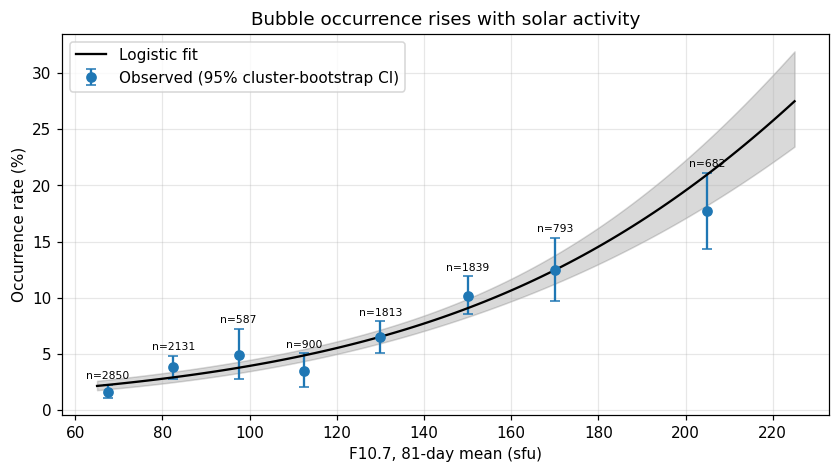

Each +10 sfu of F10.7 multiplies the odds of a bubble by 1.19 (95% CI 1.17-1.22)


,F107_fine,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
0,"(60, 75]",2850,47,1.65,1.08,2.25
1,"(75, 90]",2131,81,3.80,2.79,4.82
2,"(90, 105]",587,29,4.94,2.74,7.23
3,"(105, 120]",900,31,3.44,2.07,5.05
4,"(120, 140]",1813,118,6.51,5.09,7.89
5,"(140, 160]",1839,187,10.17,8.53,11.89
6,"(160, 180]",793,99,12.48,9.69,15.33
7,"(180, 230]",682,121,17.74,14.33,21.12


In [ ]:
bins = [60, 75, 90, 105, 120, 140, 160, 180, 230]
p["F107_fine"] = pd.cut(p["F107_81"], bins)
sf = rate_table(p.dropna(subset=["F107_fine"]), "F107_fine")
sf["mid"] = sf["F107_fine"].apply(lambda b: b.mid).astype(float)

# simple logistic curve: P(bubble) as a function of F10.7, for comparison
m1 = smf.glm("bubble ~ F107_81", data=p.dropna(subset=["F107_81"]), family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": p.dropna(subset=["F107_81"])["night_id"].astype("category").cat.codes})
grid = pd.DataFrame({"F107_81": np.linspace(65, 225, 100)})
pr = m1.get_prediction(grid).summary_frame()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(sf["mid"], sf["rate_%"], yerr=[sf["rate_%"] - sf["ci_low_%"], sf["ci_high_%"] - sf["rate_%"]],
            marker="o", capsize=3, ls="none", label="Observed (95% cluster-bootstrap CI)")
ax.plot(grid["F107_81"], 100 * pr["mean"], color="k", label="Logistic fit")
ax.fill_between(grid["F107_81"], 100 * pr["mean_ci_lower"], 100 * pr["mean_ci_upper"], color="k", alpha=0.15)
for _, r in sf.iterrows(): ax.annotate(f"n={r.n_passes}", (r["mid"], r["ci_high_%"] + 0.5), ha="center", fontsize=7)
ax.set_xlabel("F10.7, 81-day mean (sfu)"); ax.set_ylabel("Occurrence rate (%)"); ax.legend()
ax.set_title("Bubble occurrence rises with solar activity")
savefig("O1_rate_vs_F107"); plt.show()
or10 = np.exp(10 * m1.params["F107_81"]); ci10 = np.exp(10 * m1.conf_int().loc["F107_81"])
print(f"Each +10 sfu of F10.7 multiplies the odds of a bubble by {or10:.2f} (95% CI {ci10[0]:.2f}-{ci10[1]:.2f})")
display(sf.drop(columns="mid").round(2))

### Why the overall rate looks low: rates under peak conditions
The overall rate mixes all conditions together: solar minimum years, June solstice, and post-midnight hours, when bubbles are rare. The table below shows the rate when the conditions that favour bubbles come together.

In [ ]:
eq = p["season"].isin(["Mar equinox", "Sep equinox"])
evening = (p["LT"] >= 19.5) & (p["LT"] < 24)
high = p["F107_81"] > 150
cases = {
    "All night passes": p.index == p.index,
    "Equinox only": eq,
    "Evening 19:30-24 LT only": evening,
    "F10.7 > 150 only": high,
    "Equinox + evening": eq & evening,
    "Equinox + evening + F10.7 > 150": eq & evening & high,
    "Equinox + evening, 2023-2025": eq & evening & p["year"].between(2023, 2025),
    "June solstice + evening": (p["season"] == "Jun solstice") & evening,
    "Post-midnight (00-06 LT)": p["LT"] < 6,
}
rows = []
for name, m in cases.items():
    g = p[m]; lo, hi = cluster_boot_ci(g)
    rows.append({"condition": name, "n_passes": len(g), "rate_%": 100 * g["bubble"].mean(),
                 "ci_low_%": 100 * lo, "ci_high_%": 100 * hi})
peak_table = pd.DataFrame(rows); display(peak_table.round(1))
peak_table.to_csv(TAB_DIR / "O1_peak_conditions.csv", index=False)

,condition,n_passes,rate_%,ci_low_%,ci_high_%
0,All night passes,11633,6.2,5.6,6.7
1,Equinox only,3920,9.2,8.1,10.4
2,Evening 19:30-24 LT only,4476,10.1,9.0,11.2
3,F10.7 > 150 only,2563,13.2,11.6,14.8
4,Equinox + evening,1500,16.5,14.4,19.0
5,Equinox + evening + F10.7 > 150,387,35.9,30.1,41.9
6,"Equinox + evening, 2023-2025",378,40.5,35.0,46.7
7,June solstice + evening,1509,4.7,3.4,6.1
8,Post-midnight (00-06 LT),5778,3.7,3.1,4.3


---
## 9. Geomagnetic activity, and why the crude result can mislead
Kp is higher during solar maximum years, so a crude rate-by-Kp table mixes the effect of storms with the effect of solar flux (**confounding**). We therefore also look at Kp *within* each solar-activity level (stratification).

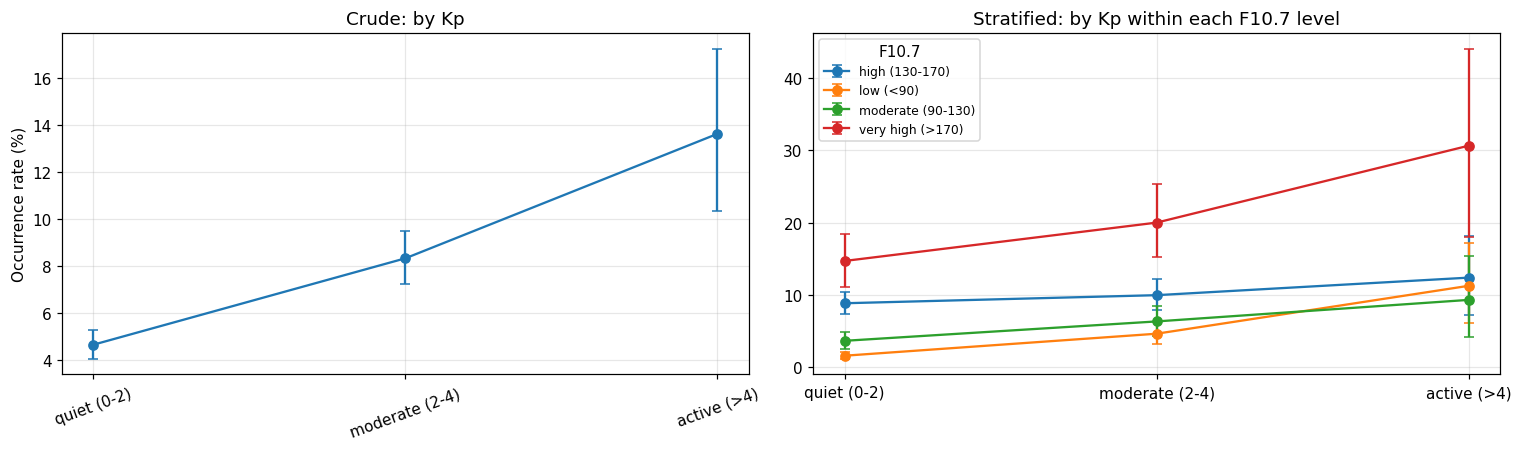

,F107_cat,Kp_cat,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
0,low (<90),quiet (0-2),3693,57,1.5,1.1,2.1
1,low (<90),moderate (2-4),1110,51,4.6,3.2,6.2
2,low (<90),active (>4),178,20,11.2,6.1,17.2
3,moderate (90-130),quiet (0-2),1551,56,3.6,2.4,4.9
4,moderate (90-130),moderate (2-4),778,49,6.3,4.2,8.5
5,moderate (90-130),active (>4),140,13,9.3,4.1,15.3
6,high (130-170),quiet (0-2),1905,168,8.8,7.3,10.4
7,high (130-170),moderate (2-4),1147,114,9.9,7.8,12.2
8,high (130-170),active (>4),194,24,12.4,7.3,18.1
9,very high (>170),quiet (0-2),504,74,14.7,11.1,18.4


Mean F10.7 in each Kp class: {'quiet (0-2)': 109.1, 'moderate (2-4)': 120.7, 'active (>4)': 125.0}


In [ ]:
kp = rate_table(p, "Kp_cat")
kp_strat = rate_table(p.dropna(subset=["F107_cat"]), ["F107_cat", "Kp_cat"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
plot_rates(kp.assign(Kp_cat=kp["Kp_cat"].astype(str)), "Kp_cat", axes[0]); axes[0].set_title("Crude: by Kp")
axes[0].set_ylabel("Occurrence rate (%)")
for f, g in kp_strat.groupby("F107_cat", observed=True):
    g = g.copy(); g["Kp_cat"] = g["Kp_cat"].astype(str)
    axes[1].errorbar(g["Kp_cat"], g["rate_%"], yerr=[g["rate_%"] - g["ci_low_%"], g["ci_high_%"] - g["rate_%"]],
                     marker="o", capsize=3, label=str(f))
axes[1].set_title("Stratified: by Kp within each F10.7 level"); axes[1].legend(fontsize=8, title="F10.7")
plt.tight_layout(); savefig("O1_rate_by_Kp"); plt.show()
display(kp_strat.round(1))
print("Mean F10.7 in each Kp class:", p.groupby("Kp_cat", observed=True)["F107_81"].mean().round(1).to_dict())

In [ ]:
p["Dst_cat"] = pd.cut(p["Dst_min24"], [-500, -100, -50, -30, 100],
                      labels=["intense storm (<-100)", "moderate storm (-100 to -50)", "weak (-50 to -30)", "quiet (>-30)"])
dst = rate_table(p.dropna(subset=["Dst_cat"]), "Dst_cat")
display(dst.round(1))

,Dst_cat,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
0,intense storm (<-100),160,21,13.1,7.5,19.4
1,moderate storm (-100 to -50),951,104,10.9,8.5,13.5
2,weak (-50 to -30),2106,155,7.4,6.0,8.7
3,quiet (>-30),8414,438,5.2,4.6,5.8


Storm-time results are explored properly in Objective 4. Here we only need to know whether geomagnetic activity matters *on average* and in which direction.

---
## 10. Solar Cycle 24 vs Cycle 25
Part of any difference between periods is simply solar flux, because Cycle 25 maximum years have high F10.7. The fair comparison is **at the same F10.7 level**.

,period,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
0,C24 decline (2014-19),5426,219,4.04,3.39,4.76
1,C25 rise (2020-22),2717,99,3.64,2.80,4.55
2,C25 maximum (2023-),3490,400,11.46,10.25,12.80


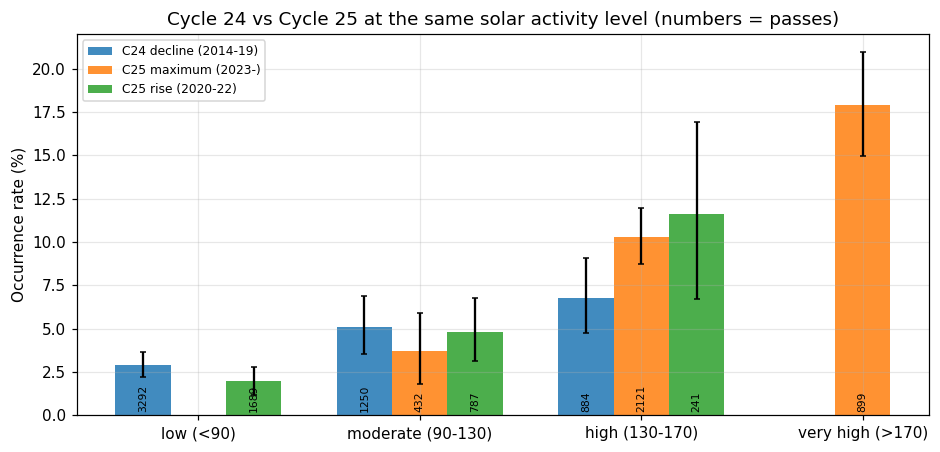

,F107_cat,period,n_passes,n_bubble,rate_%,ci_low_%,ci_high_%
0,low (<90),C24 decline (2014-19),3292,95,2.9,2.2,3.6
1,low (<90),C25 rise (2020-22),1689,33,2.0,1.2,2.8
2,moderate (90-130),C24 decline (2014-19),1250,64,5.1,3.5,6.9
3,moderate (90-130),C25 rise (2020-22),787,38,4.8,3.1,6.8
4,moderate (90-130),C25 maximum (2023-),432,16,3.7,1.8,5.9
5,high (130-170),C24 decline (2014-19),884,60,6.8,4.7,9.1
6,high (130-170),C25 rise (2020-22),241,28,11.6,6.7,16.9
7,high (130-170),C25 maximum (2023-),2121,218,10.3,8.8,12.0
8,very high (>170),C25 maximum (2023-),899,161,17.9,15.0,20.9


In [ ]:
per = rate_table(p, "period"); display(per.round(2))
cmp_tab = rate_table(p.dropna(subset=["F107_cat"]), ["F107_cat", "period"])
fig, ax = plt.subplots(figsize=(10, 4.5))
w = 0.25
for i, (per_name, g) in enumerate(cmp_tab.groupby("period", observed=True)):
    xs = np.array([f107_labels.index(str(c)) for c in g["F107_cat"]]) + (i - 1) * w
    ax.bar(xs, g["rate_%"], width=w, label=str(per_name), alpha=0.85)
    ax.errorbar(xs, g["rate_%"], yerr=[g["rate_%"] - g["ci_low_%"], g["ci_high_%"] - g["rate_%"]], fmt="none", ecolor="k", capsize=2)
    for x_, n_ in zip(xs, g["n_passes"]): ax.annotate(f"{n_}", (x_, 0.3), ha="center", fontsize=7, rotation=90)
ax.set_xticks(range(4)); ax.set_xticklabels(f107_labels); ax.set_ylabel("Occurrence rate (%)")
ax.set_title("Cycle 24 vs Cycle 25 at the same solar activity level (numbers = passes)"); ax.legend(fontsize=8)
savefig("O1_cycle_comparison_by_F107"); plt.show()
display(cmp_tab.round(1))

In [ ]:
# Mantel-Haenszel: Cycle 25 maximum vs Cycle 24 decline, stratified by F10.7 level
from statsmodels.stats.contingency_tables import StratifiedTable
tables = []
sub = p[p["period"].isin(["C24 decline (2014-19)", "C25 maximum (2023-)"])].dropna(subset=["F107_cat"])
for f, g in sub.groupby("F107_cat", observed=True):
    t = pd.crosstab(g["period"] == "C25 maximum (2023-)", g["bubble"]).reindex(index=[True, False], columns=[1, 0], fill_value=0)
    if (t.values.sum(axis=1) > 0).all():
        tables.append(t.values)
st = StratifiedTable(tables)
print(f"Mantel-Haenszel odds ratio (C25 max vs C24, same F10.7 level): {st.oddsratio_pooled:.2f} "
      f"(95% CI {st.oddsratio_pooled_confint()[0]:.2f}-{st.oddsratio_pooled_confint()[1]:.2f}), "
      f"p = {st.test_null_odds().pvalue:.4f}")
print("Test that the odds ratio is the same in every F10.7 stratum (Breslow-Day-type): p =", round(st.test_equal_odds().pvalue, 4))
print("(Mantel-Haenszel treats passes as independent, so this p-value is slightly optimistic. The cluster-robust model in Section 11 is the main test.)")

Mantel-Haenszel odds ratio (C25 max vs C24, same F10.7 level): 1.32 (95% CI 1.03-1.70), p = 0.0352
Test that the odds ratio is the same in every F10.7 stratum (Breslow-Day-type): p = 0.0132
(Mantel-Haenszel treats passes as independent, so this p-value is slightly optimistic. The cluster-robust model in Section 11 is the main test.)


---
## 11. Multivariable logistic regression (the main O1 model)
A single model estimates the effect of each factor **while holding the others fixed**:

$$\text{logit}\,P(\text{bubble}) = \beta_0 + \text{local time} + \text{season} + \text{solar activity} + \text{geomagnetic activity} + \text{satellite} + \text{cycle period}$$

- All factors are categorical, so each coefficient becomes an **odds ratio (OR)** relative to a reference group: 18–20 LT, June solstice, low F10.7, quiet Kp, Swarm A, Cycle 24.
- OR > 1 means more bubbles than the reference group; OR < 1 means fewer.
- Standard errors are **cluster-robust by night**.
- **Wald tests** check whether each factor as a whole matters.
- The satellite term checks whether Swarm B, which flies about 50 km higher, detects bubbles less often than A and C.

In [ ]:
model_df = p.dropna(subset=["F107_cat", "Kp_cat"]).copy()
for c, ref in [("LT2", "18-20"), ("season", "Jun solstice"), ("F107_cat", "low (<90)"),
               ("Kp_cat", "quiet (0-2)"), ("period", "C24 decline (2014-19)")]:
    model_df[c] = model_df[c].astype(str)
FORMULA = ("bubble ~ C(LT2, Treatment('18-20')) + C(season, Treatment('Jun solstice'))"
           " + C(F107_cat, Treatment('low (<90)')) + C(Kp_cat, Treatment('quiet (0-2)'))"
           " + C(sat, Treatment('A')) + C(period, Treatment('C24 decline (2014-19)'))")

def fit_glm(formula, df):
    groups = df["night_id"].astype("category").cat.codes
    return smf.glm(formula, data=df, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": groups})

mA = fit_glm(FORMULA, model_df)

def or_table(res):
    ci = res.conf_int()
    t = pd.DataFrame({"OR": np.exp(res.params), "CI_low": np.exp(ci[0]), "CI_high": np.exp(ci[1]), "p_value": res.pvalues})
    t.index = (t.index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.", r"\1: ", regex=True).str.rstrip("]"))
    return t.drop(index="Intercept")

ors = or_table(mA); ors.to_csv(TAB_DIR / "O1_logistic_odds_ratios.csv")
display(ors.round(3))

,OR,CI_low,CI_high,p_value
LT2: 00-02,0.783,0.542,1.132,0.194
LT2: 02-04,0.635,0.425,0.950,0.027
LT2: 04-06,0.609,0.405,0.914,0.017
LT2: 20-22,2.279,1.674,3.102,0.000
LT2: 22-24,1.926,1.404,2.642,0.000
season: Dec solstice,1.844,1.385,2.455,0.000
season: Mar equinox,3.529,2.600,4.789,0.000
season: Sep equinox,3.050,2.252,4.131,0.000
F107_cat: high (130-170),3.086,2.220,4.292,0.000
F107_cat: moderate (90-130),1.772,1.262,2.487,0.001


In [ ]:
wald = mA.wald_test_terms(skip_single=False, scalar=True)
wt = wald.summary_frame()
wt.index = wt.index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)", r"\1", regex=True)
display(wt.round(4))
wt.to_csv(TAB_DIR / "O1_wald_tests.csv")

from sklearn.metrics import roc_auc_score
model_df["p_hat"] = mA.predict(model_df)
print(f"In-sample ROC-AUC of the model: {roc_auc_score(model_df['bubble'], model_df['p_hat']):.3f}")
cal = model_df.groupby(pd.qcut(model_df["p_hat"], 10, duplicates="drop"), observed=True).agg(
    predicted=("p_hat", "mean"), observed=("bubble", "mean"), n=("bubble", "size"))
display((cal[["predicted", "observed"]] * 100).round(1).assign(n=cal["n"]))

,chi2,P>chi2,df constraint
Intercept,451.9503,0.0000,1
LT2,112.8501,0.0000,5
season,80.0190,0.0000,3
F107_cat,83.2134,0.0000,3
Kp_cat,36.3854,0.0000,2
sat,4.1798,0.1237,2
period,2.1666,0.3385,2


In-sample ROC-AUC of the model: 0.768


,predicted,observed,n
p_hat,,,
"(0.00394, 0.00976]",0.7,1.5,1169
"(0.00976, 0.0161]",1.3,2.0,1153
"(0.0161, 0.021]",1.8,2.6,1166
"(0.021, 0.0286]",2.5,2.2,1153
"(0.0286, 0.037]",3.3,2.3,1174
"(0.037, 0.0506]",4.4,4.2,1154
"(0.0506, 0.0646]",5.7,4.6,1147
"(0.0646, 0.0921]",7.6,6.6,1164
"(0.0921, 0.141]",11.3,10.3,1156


**Reading the calibration table:** passes are split into 10 groups by predicted probability. If the "predicted" and "observed" columns are close in every group, the model describes the data well.

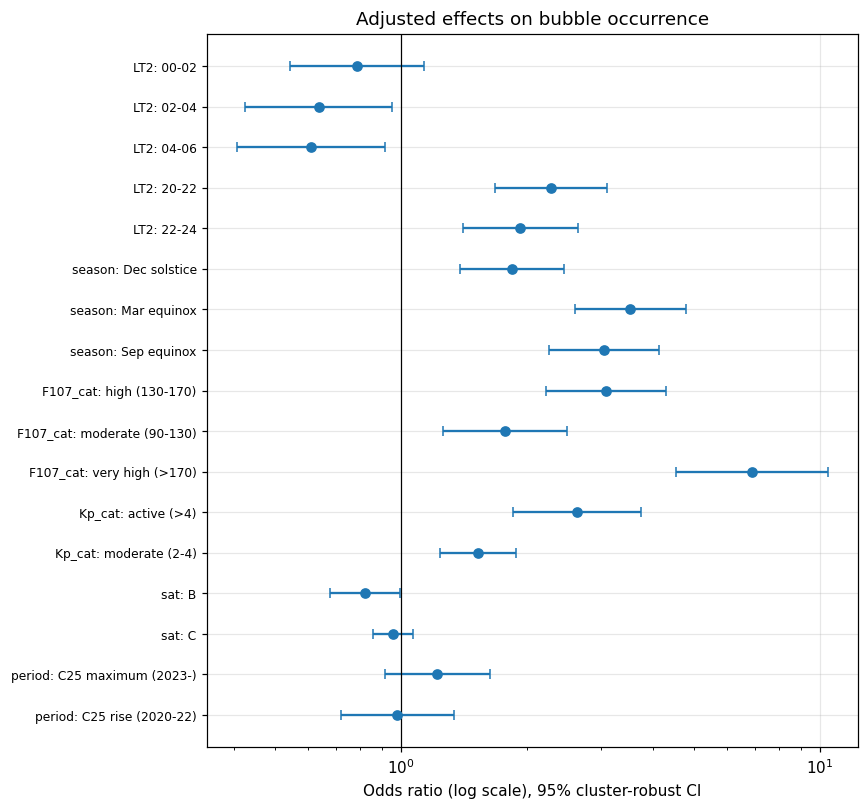

In [ ]:
# Forest plot of odds ratios
fig, ax = plt.subplots(figsize=(8, 0.38 * len(ors) + 1))
y = np.arange(len(ors))[::-1]
ax.errorbar(ors["OR"], y, xerr=[ors["OR"] - ors["CI_low"], ors["CI_high"] - ors["OR"]], fmt="o", capsize=3)
ax.axvline(1, color="k", lw=0.8); ax.set_xscale("log")
ax.set_yticks(y); ax.set_yticklabels(ors.index, fontsize=8)
ax.set_xlabel("Odds ratio (log scale), 95% cluster-robust CI")
ax.set_title("Adjusted effects on bubble occurrence")
plt.tight_layout(); savefig("O1_forest_plot"); plt.show()

### Model-based climatology (smooth curves)
A second model treats local time, season and F10.7 as **smooth** effects:
- a spline in local time
- annual and semi-annual harmonics of day-of-year
- a spline in F10.7

It then predicts the bubble probability for typical conditions. These curves are easier to read than raw rates in small bins, and they make a good summary figure for the paper.

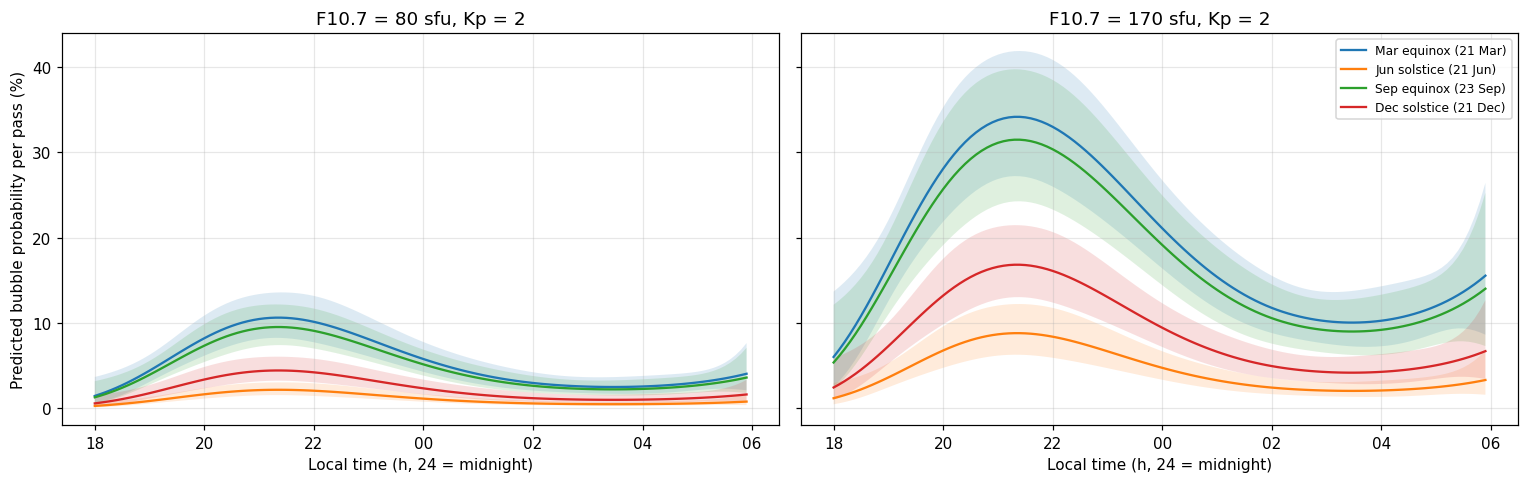

In [ ]:
sm_df = p.dropna(subset=["F107_81"]).copy()
for k in (1, 2):
    sm_df[f"s{k}"] = np.sin(2 * np.pi * k * sm_df["doy"] / 365.25)
    sm_df[f"c{k}"] = np.cos(2 * np.pi * k * sm_df["doy"] / 365.25)
mB = fit_glm("bubble ~ bs(LT_from18, df=5, lower_bound=0, upper_bound=12) + s1 + c1 + s2 + c2 + bs(F107_81, df=3, lower_bound=60, upper_bound=230) + Kp + C(sat)", sm_df)

doys = {"Mar equinox (21 Mar)": 80, "Jun solstice (21 Jun)": 172, "Sep equinox (23 Sep)": 266, "Dec solstice (21 Dec)": 355}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, f in zip(axes, [80, 170]):
    for name, d in doys.items():
        g = pd.DataFrame({"LT_from18": np.linspace(0, 11.9, 120)})
        g["s1"], g["c1"] = np.sin(2*np.pi*d/365.25), np.cos(2*np.pi*d/365.25)
        g["s2"], g["c2"] = np.sin(4*np.pi*d/365.25), np.cos(4*np.pi*d/365.25)
        g["F107_81"], g["Kp"], g["sat"] = f, 2.0, "A"
        fr = mB.get_prediction(g).summary_frame()
        ax.plot(g["LT_from18"] + 18, 100 * fr["mean"], label=name)
        ax.fill_between(g["LT_from18"] + 18, 100 * fr["mean_ci_lower"], 100 * fr["mean_ci_upper"], alpha=0.15)
    ax.set_title(f"F10.7 = {f} sfu, Kp = 2"); ax.set_xlabel("Local time (h, 24 = midnight)")
    ax.set_xticks(range(18, 31, 2)); ax.set_xticklabels([f"{h%24:02d}" for h in range(18, 31, 2)])
axes[0].set_ylabel("Predicted bubble probability per pass (%)"); axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("O1_model_climatology"); plt.show()

---
## 12. Sensitivity checks
Do the main conclusions survive if we:
1. use the **stricter label** `bubble10` (at least 10 s of bubble)?
2. **drop Swarm C**, removing most of the A–C double counting?
3. **drop passes in storm periods** (Dst_min24 < −50 nT)?

We compare the key odds ratios across these versions. If they keep the same direction and similar size, the result is robust.

In [ ]:
versions = {
    "Main model": (model_df, "bubble"),
    "Stricter label (>= 10 s)": (model_df, "bubble10"),
    "Without Swarm C": (model_df[model_df["sat"] != "C"], "bubble"),
    "Without storm periods": (model_df[model_df["Dst_min24"] > -50], "bubble"),
}
key_terms = ["LT2: 20-22", "LT2: 02-04", "season: Mar equinox", "season: Sep equinox", "season: Dec solstice",
             "F107_cat: high (130-170)", "F107_cat: very high (>170)", "Kp_cat: active (>4)",
             "sat: B", "period: C25 maximum (2023-)"]
sens = {}
for name, (df, target) in versions.items():
    f = FORMULA.replace("bubble ~", f"{target} ~")
    r = or_table(fit_glm(f, df))
    sens[name] = r["OR"].reindex(key_terms).round(2).astype(str) + " (" + r["CI_low"].reindex(key_terms).round(2).astype(str) + \
                 "-" + r["CI_high"].reindex(key_terms).round(2).astype(str) + ")"
sens = pd.DataFrame(sens); sens.to_csv(TAB_DIR / "O1_sensitivity.csv")
display(sens)

,Main model,Stricter label (>= 10 s),Without Swarm C,Without storm periods
LT2: 20-22,2.28 (1.67-3.1),2.9 (1.98-4.25),2.25 (1.64-3.09),2.82 (2.0-3.98)
LT2: 02-04,0.64 (0.42-0.95),0.72 (0.44-1.19),0.63 (0.42-0.94),0.73 (0.46-1.14)
season: Mar equinox,3.53 (2.6-4.79),3.99 (2.79-5.72),3.11 (2.28-4.23),3.43 (2.46-4.78)
season: Sep equinox,3.05 (2.25-4.13),2.98 (2.07-4.3),2.92 (2.15-3.96),3.24 (2.33-4.51)
season: Dec solstice,1.84 (1.39-2.46),2.1 (1.49-2.95),1.75 (1.32-2.33),1.86 (1.37-2.54)
F107_cat: high (130-170),3.09 (2.22-4.29),3.24 (2.2-4.77),2.58 (1.85-3.59),3.42 (2.39-4.88)
F107_cat: very high (>170),6.89 (4.53-10.49),7.2 (4.41-11.73),5.07 (3.31-7.74),7.41 (4.69-11.69)
Kp_cat: active (>4),2.63 (1.85-3.74),2.84 (1.92-4.2),2.74 (1.91-3.93),3.4 (2.01-5.73)
sat: B,0.82 (0.68-0.99),0.84 (0.66-1.06),0.82 (0.68-0.99),0.85 (0.69-1.05)
period: C25 maximum (2023-),1.22 (0.92-1.63),1.16 (0.83-1.62),1.48 (1.1-1.98),1.33 (0.97-1.82)


---
## 13. Summary of findings (filled in from your data)

In [ ]:
def r_(t, col, val):
    row = t[t[col].astype(str) == str(val)].iloc[0]
    return f"{row['rate_%']:.1f}% (95% CI {row['ci_low_%']:.1f}-{row['ci_high_%']:.1f}%)"

pk = peak_table.set_index("condition")
lines = [
    f"Passes analysed: {len(p):,} night passes on {p['night_id'].nunique():,} nights, {p['year'].min()}-{p['year'].max()}.",
    f"Overall occurrence: {overall['rate_%'].iloc[0]:.1f}% of night passes.",
    f"Peak local time: {int(peak['LT_h']):02d}-{(int(peak['LT_h'])+1)%24:02d} LT ({peak['rate_%']:.1f}%); post-midnight 00-06 LT: {pk.loc['Post-midnight (00-06 LT)','rate_%']:.1f}%.",
    "Season: " + "; ".join(f"{s} {r_(se, 'season', s)}" for s in season_order) + ".",
    f"Solar activity: +10 sfu multiplies the odds by {or10:.2f}; rate in yearly data correlates with F10.7 (Spearman rho = {rho:.2f}).",
    f"Under peak conditions (equinox, 19:30-24 LT, F10.7 > 150) the rate is {pk.loc['Equinox + evening + F10.7 > 150','rate_%']:.1f}%, "
    f"compared with {pk.loc['June solstice + evening','rate_%']:.1f}% for June-solstice evenings.",
    f"Cycle 25 max vs Cycle 24 at the same F10.7 (Mantel-Haenszel OR): {st.oddsratio_pooled:.2f} "
    f"({st.oddsratio_pooled_confint()[0]:.2f}-{st.oddsratio_pooled_confint()[1]:.2f}).",
    f"Adjusted OR for C25 maximum (main model): {ors.loc['period: C25 maximum (2023-)','OR']:.2f} "
    f"({ors.loc['period: C25 maximum (2023-)','CI_low']:.2f}-{ors.loc['period: C25 maximum (2023-)','CI_high']:.2f}).",
    f"Adjusted OR for active Kp (>4) vs quiet: {ors.loc['Kp_cat: active (>4)','OR']:.2f} "
    f"({ors.loc['Kp_cat: active (>4)','CI_low']:.2f}-{ors.loc['Kp_cat: active (>4)','CI_high']:.2f}).",
    f"Swarm B vs A (adjusted OR): {ors.loc['sat: B','OR']:.2f} ({ors.loc['sat: B','CI_low']:.2f}-{ors.loc['sat: B','CI_high']:.2f}).",
]
summary = "\n".join("- " + l for l in lines)
print(summary)
_ = (TAB_DIR / "O1_summary.txt").write_text(summary)

- Passes analysed: 11,633 night passes on 4,607 nights, 2014-2026.
- Overall occurrence: 6.2% of night passes.
- Peak local time: 20-21 LT (12.2%); post-midnight 00-06 LT: 3.7%.
- Season: Mar equinox 9.2% (95% CI 7.6-11.1%); Jun solstice 3.2% (95% CI 2.5-3.9%); Sep equinox 9.2% (95% CI 7.7-10.8%); Dec solstice 6.1% (95% CI 5.2-7.1%).
- Solar activity: +10 sfu multiplies the odds by 1.19; rate in yearly data correlates with F10.7 (Spearman rho = 0.91).
- Under peak conditions (equinox, 19:30-24 LT, F10.7 > 150) the rate is 35.9%, compared with 4.7% for June-solstice evenings.
- Cycle 25 max vs Cycle 24 at the same F10.7 (Mantel-Haenszel OR): 1.32 (1.03-1.70).
- Adjusted OR for C25 maximum (main model): 1.22 (0.92-1.63).
- Adjusted OR for active Kp (>4) vs quiet: 2.63 (1.85-3.74).
- Swarm B vs A (adjusted OR): 0.82 (0.68-0.99).


### Interpretation guide for the write-up
- **Why the overall rate is low.** A single satellite pass samples one thin cut through the sky and lasts about 10 minutes. The overall figure also averages over solar minimum years, solstices and post-midnight hours, when bubbles are rare. Under favourable conditions the rate is several times higher (Section 8). Ground-based instruments such as airglow imagers see a much larger area for the whole night, so their nightly occurrence rates are higher and are **not directly comparable** with per-pass rates.
- **Physics checks.** The results should show:
  - an evening peak followed by a decline after midnight (pre-reversal enhancement timing)
  - equinox maxima and a June-solstice minimum (sunset alignment with the magnetic field lines in this longitude sector)
  - a strong increase with F10.7

  If all three appear, the dataset behaves as expected.
- **Cycle 25.** Report both the crude difference and the difference **at the same F10.7** (Section 10 and the period OR in Section 11). Only the adjusted result says whether Cycle 25 is unusual.
- **Geomagnetic activity.** The crude Kp effect is partly solar-cycle confounding. Quote the adjusted OR, and leave the storm-by-storm analysis to Objective 4.